In [16]:
from langgraph.graph import StateGraph,START,END
from langchain.chat_models import init_chat_model
from langchain_core.messages import SystemMessage,HumanMessage,AIMessage,BaseMessage

from langgraph.graph.message import add_messages
from typing import TypedDict,Literal,Annotated
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv
from langgraph.types import interrupt,Command

In [17]:
load_dotenv()

True

In [18]:
llm=init_chat_model(
    model="openai/gpt-oss-120b",
    model_provider="groq"
)

In [19]:
class ChatState(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]

In [20]:
def print_msg(state:ChatState):
    print(state["messages"])

print_msg(ChatState)

__main__.ChatState['messages']


In [30]:

def chat_node(state: ChatState):
    decision = interrupt({
        "type": "approval",
        "reason": "The model is about to answer a question",
        "question": state["messages"][-1].content,
        "instruction": "Approve this question? Enter yes or no."
    })

    if decision["approved"].strip().lower() != "yes":
        return {
            "messages": [
                AIMessage(content="Not approved. I will not answer this question.")
            ]
        }

    response = llm.invoke(state["messages"])
    return {"messages": [response]}


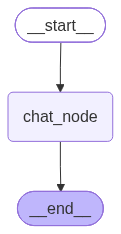

In [31]:
checkpointer=InMemorySaver()

graph=StateGraph(ChatState)
graph.add_node("chat_node",chat_node)
graph.add_edge(START,"chat_node")
graph.add_edge("chat_node",END)

workflow=graph.compile(checkpointer=checkpointer)
workflow

In [32]:
config={"configurable":{"thread_id":"thread_1"}}
initial_state={
    "messages":[HumanMessage(content="what is Artificial Intelligence")]
}
response=workflow.invoke(initial_state,config=config)

In [33]:
response

{'messages': [HumanMessage(content='what is Artificial Intelligence', additional_kwargs={}, response_metadata={}, id='bd91a4e0-9b81-48ca-bc67-1e4651efba2b')],
 '__interrupt__': [Interrupt(value={'type': 'approval', 'reason': 'The model is about to answer a question', 'question': 'what is Artificial Intelligence', 'instruction': 'Approve this question? Enter yes or no.'}, id='492aec504cb5b3746be422649259d7c0', response_schema=None)]}

In [34]:
message=response["__interrupt__"][0].value
message

{'type': 'approval',
 'reason': 'The model is about to answer a question',
 'question': 'what is Artificial Intelligence',
 'instruction': 'Approve this question? Enter yes or no.'}

In [43]:

user_input = input("Approve this question? (yes/no): ").strip().lower()

if user_input not in {"yes", "no"}:
    raise ValueError("Please enter only 'yes' or 'no'.")


In [44]:
print(user_input)

yes


In [41]:
final_result=workflow.invoke(
    Command(resume={"approved":user_input}),
    config=config
)
final_result

{'messages': [HumanMessage(content='what is Artificial Intelligence', additional_kwargs={}, response_metadata={}, id='bd91a4e0-9b81-48ca-bc67-1e4651efba2b'),
  AIMessage(content='**Artificial Intelligence (AI)** is a branch of computer science that aims to create machines—software, hardware, or a combination of both—that can **perform tasks that normally require human intelligence**. These tasks include learning, reasoning, problem‑solving, perception, language understanding, and even creativity.\n\n---\n\n## Core Idea\nAt its heart, AI is about **building systems that can adapt, improve, and make decisions** based on data and experience, rather than following a rigid set of pre‑programmed instructions.\n\n---\n\n## Major Sub‑fields & Techniques\n\n| Sub‑field | What It Does | Typical Techniques |\n|-----------|--------------|--------------------|\n| **Machine Learning (ML)** | Enables computers to learn patterns from data. | Supervised/unsupervised learning, decision trees, SVMs, neur

In [42]:
final_result["messages"][-1].content

'**Artificial Intelligence (AI)** is a branch of computer science that aims to create machines—software, hardware, or a combination of both—that can **perform tasks that normally require human intelligence**. These tasks include learning, reasoning, problem‑solving, perception, language understanding, and even creativity.\n\n---\n\n## Core Idea\nAt its heart, AI is about **building systems that can adapt, improve, and make decisions** based on data and experience, rather than following a rigid set of pre‑programmed instructions.\n\n---\n\n## Major Sub‑fields & Techniques\n\n| Sub‑field | What It Does | Typical Techniques |\n|-----------|--------------|--------------------|\n| **Machine Learning (ML)** | Enables computers to learn patterns from data. | Supervised/unsupervised learning, decision trees, SVMs, neural networks. |\n| **Deep Learning** | A subset of ML using multi‑layered neural networks to model complex patterns. | Convolutional nets (images), recurrent nets (sequences), tra